# Predicting traffic impact at the start of an accident

Group members: [ADD ALL NAMES]

## Introduction

Can a full context model identify incidents assigned upper traffic-impact levels at accident start, and do its performances persist in the following year?

The full model combines 33 admissible inputs. Simple rules are benchmarks, not the main objective. Our contribution is temporal evaluation with information-availability checks and model diagnostics, not a new algorithm. This framing was revised after the experiments without changing frozen choices or scores.

## Target definition

Severity is an ordered scale from 1 to 4 describing traffic impact. The creator describes 1 as the least impact with short delay and 4 as significant impact with long delay. No precise delay-minute boundaries between levels are supplied. This is not injury severity.

We retain binary y = (Severity >= 3): levels 3 and 4 are positive, levels 1 and 2 negative. High impact is our study grouping of the upper levels, not an official operational cutoff. About 33.89% of Source2 records in 2016-2021 are positive before cleaning; about 98.77% of these positives are level 3. Binary scores do not establish good level-4 detection.

Start_Time is the retrospective prediction-time proxy. Publication times and the time Severity was assigned are unknown, so first-report deployment is not validated.

Source: https://www.kaggle.com/sobhanmoosavi/us-accidents/metadata (accessed 2026-10-03). Detailed source-grounded target documentation accompanies this notebook in DOCUMENTATION_CIBLE.md.

Related work: https://github.com/Simranghag22/us-accidents-severity-prediction and https://github.com/JustinJ-Lo/vehicle-severity-ml. Their scores are not directly comparable to ours.


In [ ]:
from pathlib import Path
import sys
ROOT = Path.cwd()
while not (ROOT / "traffic_impact").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "traffic_impact").exists(), "Open this notebook inside the repository."
sys.path.insert(0, str(ROOT))
from traffic_impact.experiment import FeatureBuilder, Model, score, threadpool_limits
import pandas as pd
import json
RESULTS = ROOT / "results"


## Preprocessing

Full streaming audit; uniformly sampled distinct events from Source2. Train: 2016-2019, validation: 2020, untouched test: 2021, stress: available 2022. Weather observations outside the preceding two-hour window are masked. Future information is diagnostic only. Category vocabularies, numeric imputations, thresholds and constant removal are fitted on training data. Conflicting duplicate-event labels are excluded.


In [ ]:
audit = json.loads((ROOT / "results" / "audit" / "audit.json").read_text(encoding="utf-8"))
display(pd.DataFrame(audit["samples"]).T)
display(pd.read_csv(ROOT / "results" / "audit" / "columns.csv").sort_values("missing_pct", ascending=False).head(12))


In [ ]:
selection = json.loads((RESULTS / "frozen_selection.json").read_text(encoding="utf-8"))
if (ROOT / "data" / "cache" / "train.pkl").exists():
    raw_train = pd.read_pickle(ROOT / "data" / "cache" / "train.pkl")
    builder = FeatureBuilder().fit(raw_train)
    X_train = builder.transform(raw_train)
    y_train = (raw_train["Severity"] >= 3).astype(int).to_numpy()
    assert not {"Severity", "Source", "ID", "Distance(mi)", "duration_min"} & set(X_train.columns)
display(pd.Series(selection["feature_groups"], name="group").to_frame())


## Training

The central comparison is a constant prior, full logistic regression and full histogram gradient boosting with all 33 admissible inputs. Select hyperparameters using 2020 validation AP and freeze choices before future-year evaluation. Single-variable rules, pair trees and feature budgets are supplementary non-triviality and redundancy diagnostics.

The modules prepare.py, experiment.py, run_study.py and render_report.py and DOCUMENTATION_CIBLE.md must accompany this notebook. Run `pip install -r requirements.txt` in your environment.


In [ ]:
# The full reproducible pipeline audits, fits, freezes selection, and evaluates.
# Set True only when intentionally rerunning the complete experiment.
RUN_FULL_STUDY = False
if RUN_FULL_STUDY:
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "scripts" / "run_study.py"), "--rerun"], check=True)


In [ ]:
selection = json.loads((RESULTS / "frozen_selection.json").read_text(encoding="utf-8"))
display(pd.read_csv(RESULTS / "single_variables.csv").head(10))
display(pd.read_csv(RESULTS / "pair_rules.csv").head(5))
print((RESULTS / "best_pair_rule.txt").read_text(encoding="utf-8"))
display(pd.read_csv(RESULTS / "best_single_category_rates.csv"))


## Evaluation

Primary metrics are Average Precision and recall in the highest-ranked 10% of incidents, supplemented by precision and ROC-AUC. Resolve ties reproducibly without target information. Compare models on the same samples. Paired weekly bootstrap intervals use 500 draws. Group ablations explain incremental information, not causal effects. Probabilities are not validated by calibration.

The five-recall-point criterion belongs to the historical complexity comparison, a secondary analysis rather than an operational guarantee or a new success criterion for the reframed prediction task.


In [ ]:
scores = pd.read_csv(RESULTS / "heldout_models.csv")
display(scores[scores["name"].isin(["prior", "best_single_rule", "best_pair_rule",
    "logistic_full", selection["best_nonlinear_pair"], "hgb_full"])])
display(pd.read_csv(RESULTS / "paired_weekly_intervals.csv"))
display(pd.read_csv(RESULTS / "group_ap_gains.csv"))
display(pd.read_csv(RESULTS / "near_duplicate_sensitivity.csv"))
display(pd.read_csv(RESULTS / "geographic_pairs_heldout.csv"))
display(pd.read_csv(RESULTS / "geographic_pairs_intervals.csv"))


In [ ]:
from IPython.display import Image, display
for name in ["01_rules_vs_ml.png", "02_feature_budget.png", "03_group_ablation.png",
             "04_learning_curve.png", "05_monthly_performance.png", "06_source_drift.png",
             "07_paired_intervals.png"]:
    display(Image(filename=str(ROOT / "figures" / name)))


### Recorded 2021 results

| model | features | ap | recall10 | precision10 |
| --- | --- | --- | --- | --- |
| prior | 0 | 0.3427 | 0.0977 | 0.335 |
| best_single_rule | 1 | 0.4118 | 0.1425 | 0.4884 |
| best_pair_rule | 2 | 0.4701 | 0.1504 | 0.5155 |
| logistic_full | 33 | 0.5667 | 0.1938 | 0.6643 |
| hgb_pair_2 | 2 | 0.4991 | 0.1506 | 0.5161 |
| geo_pair_Start_Lat_Start_Lng | 2 | 0.6046 | 0.1978 | 0.6778 |
| pair_plus_geography | 6 | 0.6827 | 0.2285 | 0.7831 |
| hgb_full | 33 | 0.7031 | 0.2338 | 0.8013 |

Geographic pairs are supplementary checks; the primary selection remains frozen.


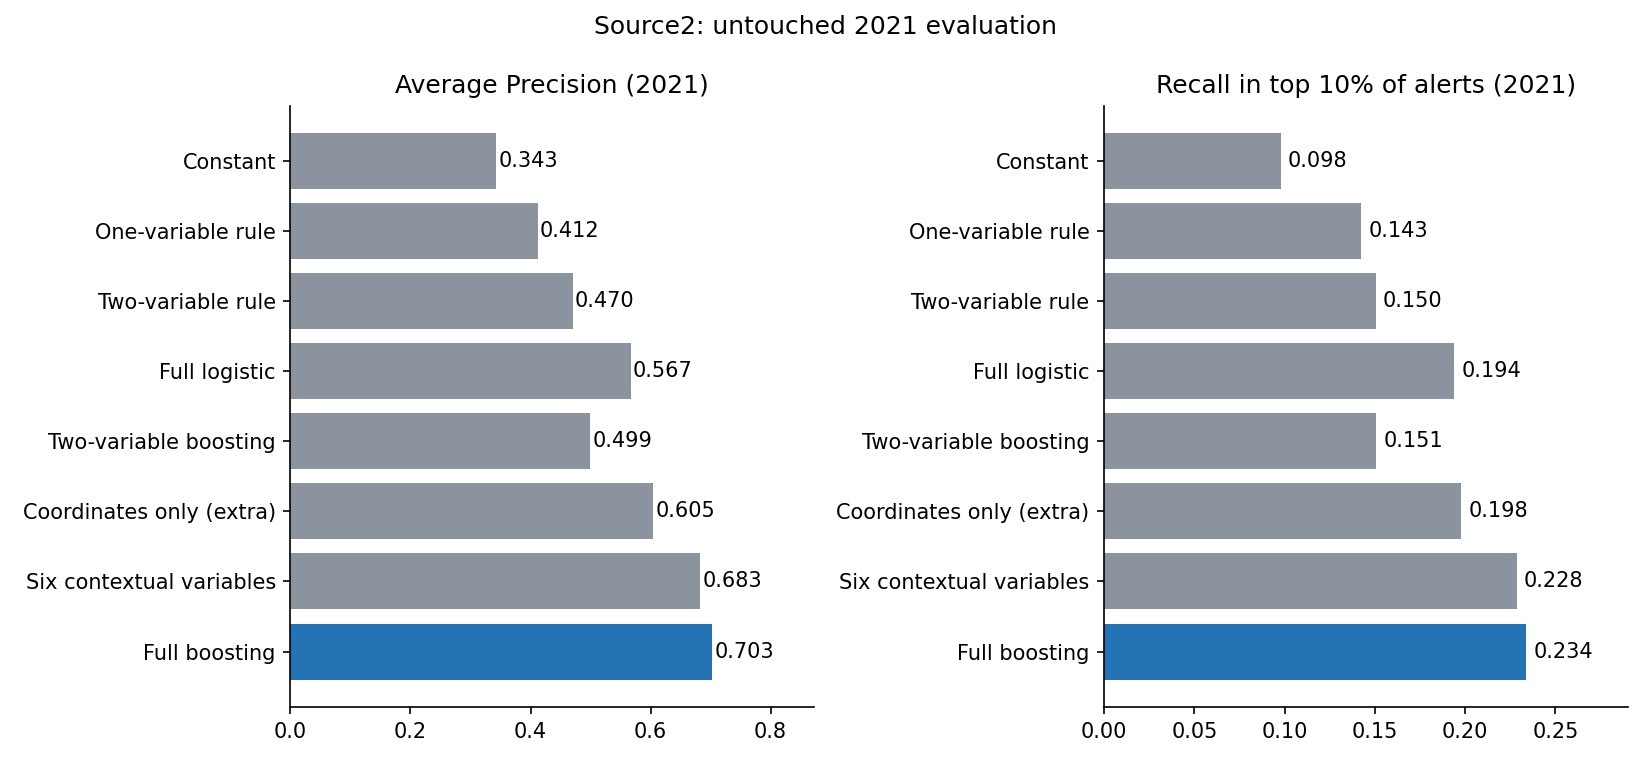


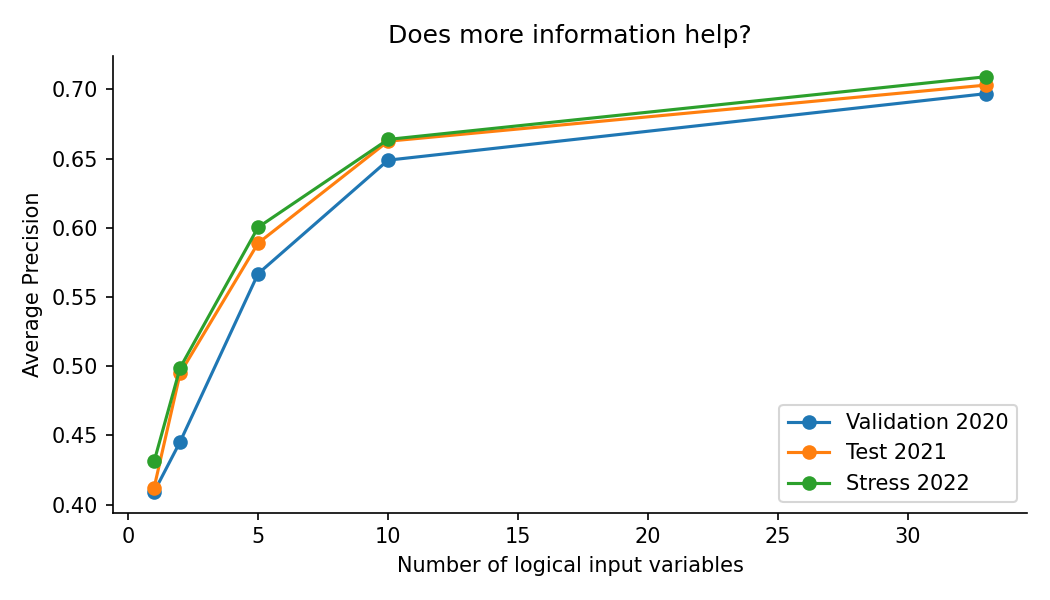


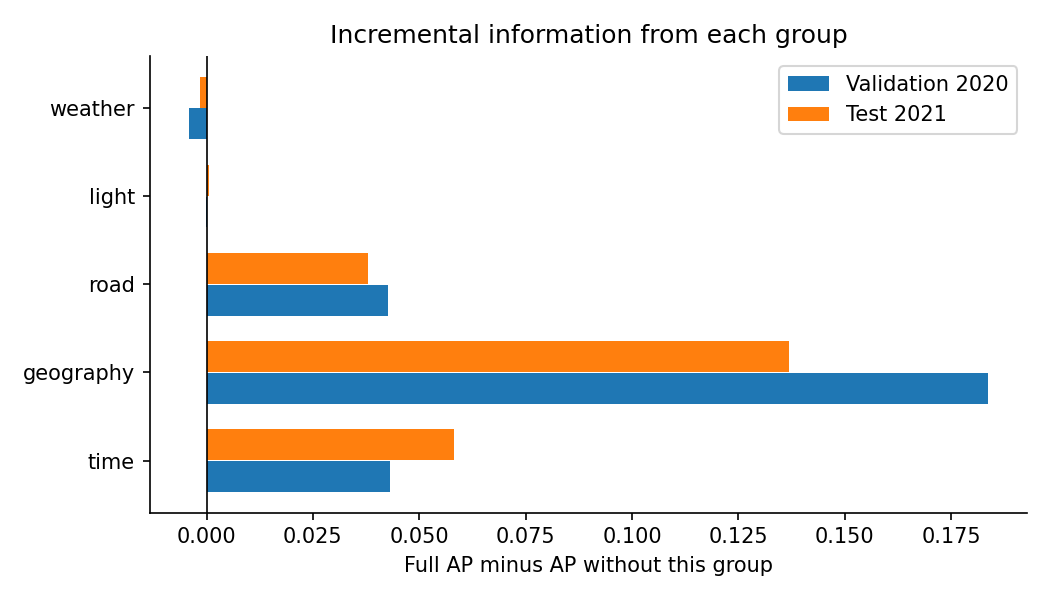


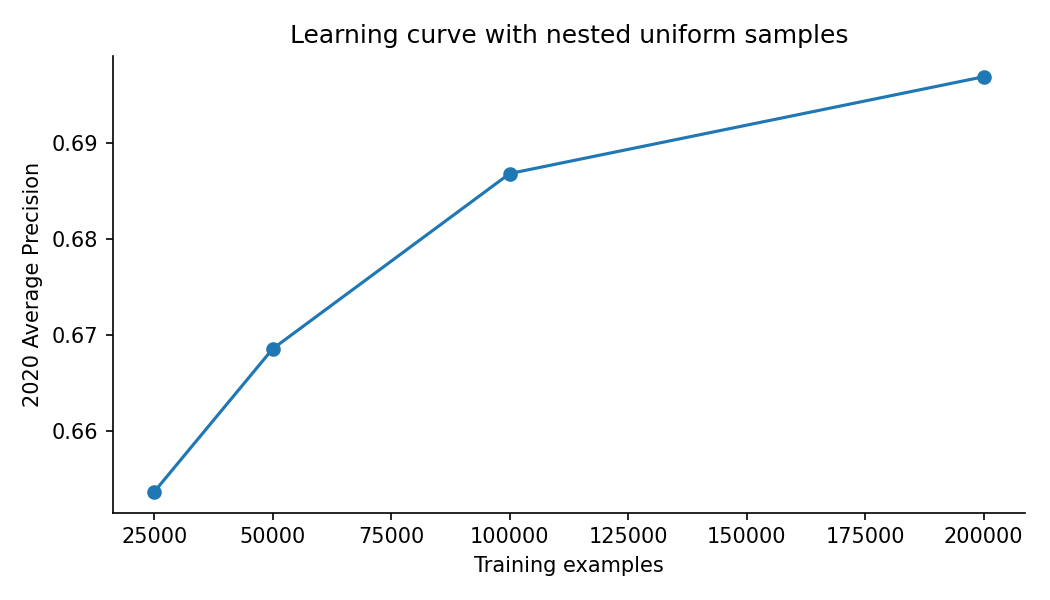


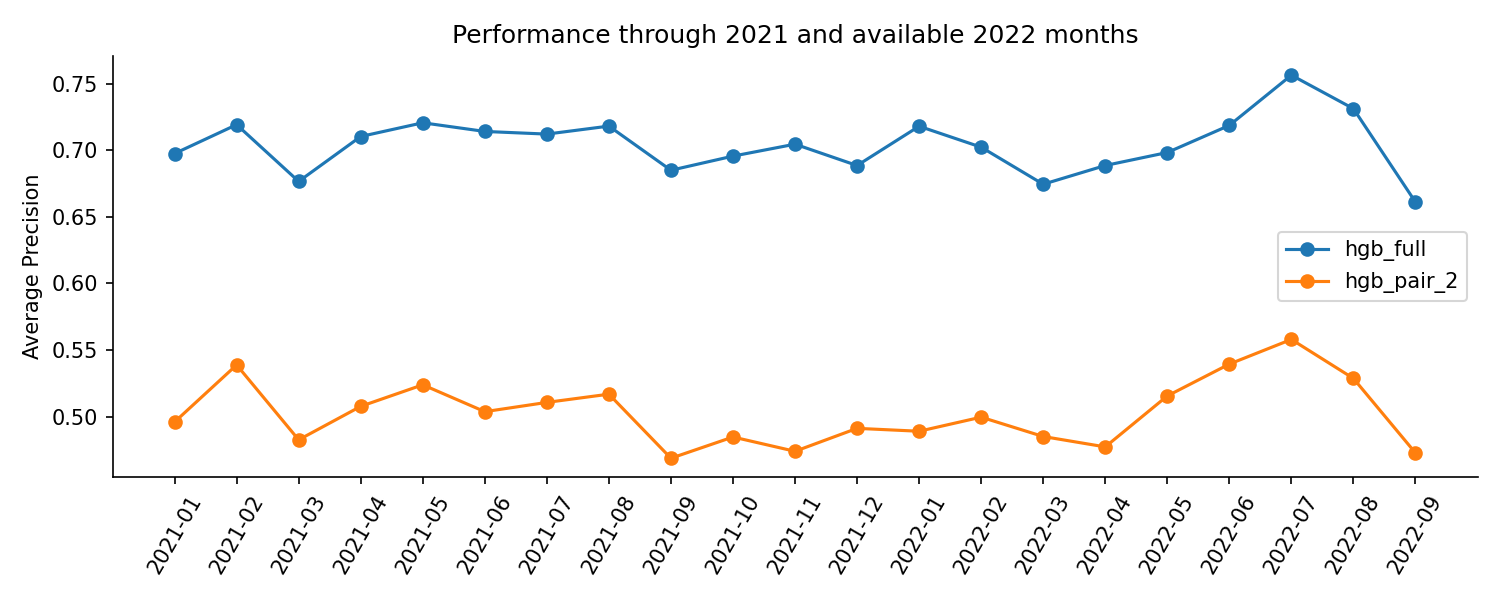


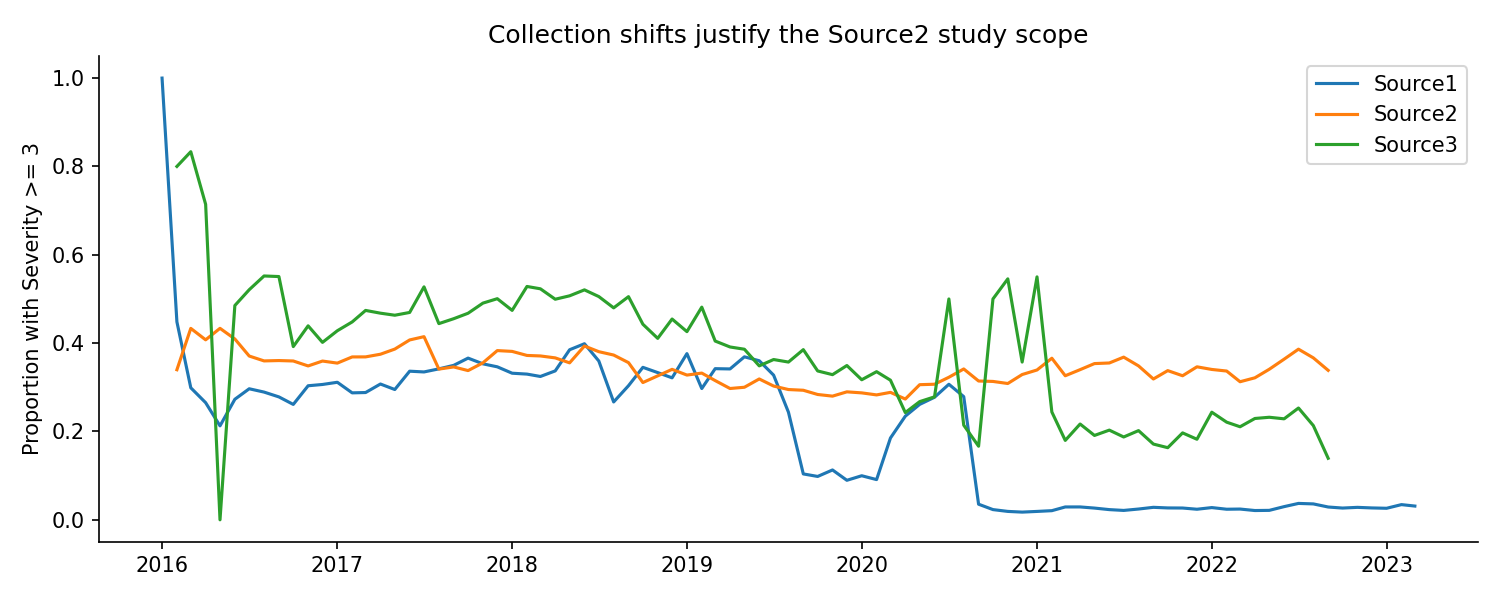


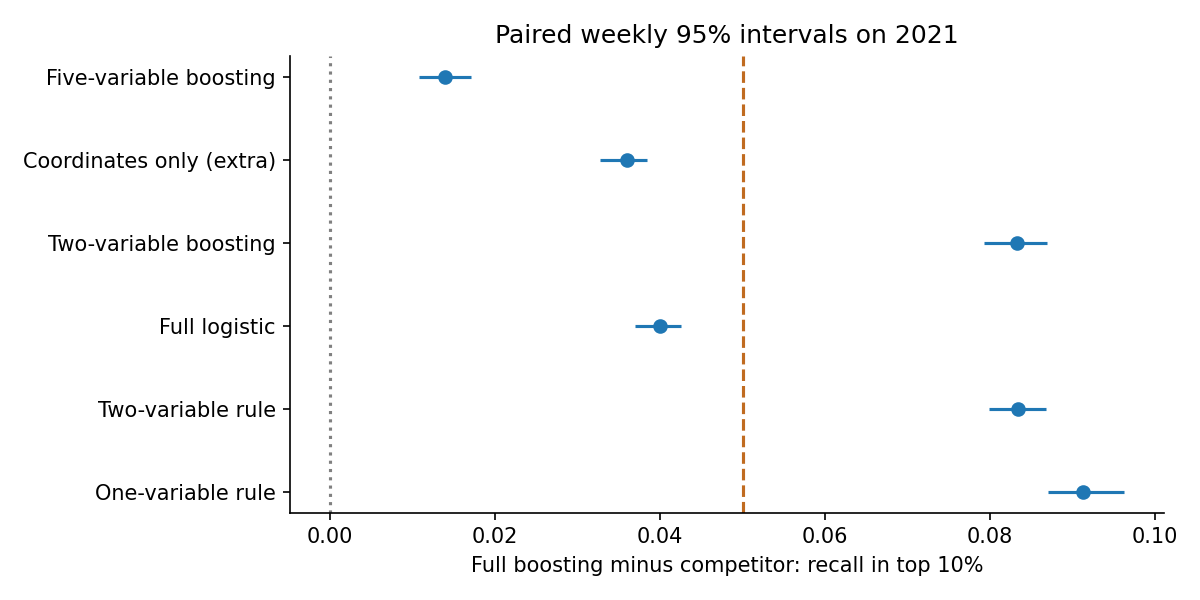


## Conclusion

The full 33-input model predicts the recorded upper traffic-impact levels (Severity 3 or 4), rather than injury severity or delay minutes. On the 2021 temporal holdout it reaches AP 0.7031 and ROC-AUC 0.8362, compared with AP 0.5667 for full logistic regression and 0.3427 for the no-information reference.

Within the highest-ranked 10% of incidents, precision is 80.13% and recall is 23.38%. On the available 2022 period, AP remains 0.7092. This supports temporal ranking performance in the studied provider, not exhaustive detection or deployment readiness. Probabilities have not been validated by calibration.

Simple rules, feature budgets and geographic pairs are secondary diagnostics. They do not establish that all 33 inputs are necessary. The historical five-recall-point criterion judged incremental complexity; it is not a newly preregistered success criterion for this reframed predictive question. The framing changed after the experiments, with scores and frozen selection preserved.

Available Source2 observations end on 2022-09-08. Most positive incidents are Severity 3; the binary scores alone do not establish good detection of Severity 4.

This study establishes predictive comparisons for recorded incidents from one provider. Group ablations do not establish causal effects, and timestamp filtering does not guarantee that weather was published at first report. With more time we would investigate road type, independent providers, repeated time windows and probability calibration.
